# Partie 1 : la décision et la mesure (notebook assemblé)

| Porteur | Nom | Étapes |
|---|---|---|
| **P1** | SANNI Farhanou Kankou | 1.1 inventorier la table, 1.7 doublons, 1.8 fuites, 1.11 la métrique |
| **P2** | FANOU Précieux | 1.2 charger et compter, 1.3 typer, 1.5 valeurs impossibles, 1.10 le plancher |
| **P3** | HOUNGBO Gwenaël | 1.4 cardinalités, 1.6 trous, 1.9 la cible (et un brouillon de 1.12, attribué à P4) |

**Comment lire ce notebook.** Les étapes suivent l'ordre de l'énoncé (1.1 à 1.12). Le code de chaque porteur est repris tel qu'il l'a écrit ; seules les lectures de fichiers ont été regroupées dans la cellule « Chargement commun », pour que tout le monde travaille sur les mêmes tableaux. Exécuter les cellules **dans l'ordre** (Run All).

## Chargement commun

Lecture unique des deux fichiers, avec la méthode de P2 : les 116 catégorielles sont lues comme du **texte**, et le texte `NA` reste une vraie modalité (il ne devient pas une valeur manquante). Les alias ci-dessous permettent à chaque porteur de garder ses propres noms de variables.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

RACINE_KAGGLE = Path("/kaggle/input")

if RACINE_KAGGLE.exists():
    trouves = [p for p in RACINE_KAGGLE.rglob("train.csv") if "sujet-04" in str(p)]
    if not trouves:
        raise FileNotFoundError("train.csv du sujet 04 introuvable : ajoutez votre jeu (Add Input).")
    DOSSIER = trouves[0].parent
else:
    DOSSIER = Path(".")

CHEMIN_TRAIN = DOSSIER / "train.csv"
CHEMIN_A_ESTIMER = DOSSIER / "a_estimer.csv"

COLS_CAT = [f"cat{i}" for i in range(1, 117)]
COLS_CONT = [f"cont{i}" for i in range(1, 15)]

types_lecture = {c: str for c in COLS_CAT}
train = pd.read_csv(CHEMIN_TRAIN, dtype=types_lecture, keep_default_na=False, na_values=[""])
a_estimer = pd.read_csv(CHEMIN_A_ESTIMER, dtype=types_lecture, keep_default_na=False, na_values=[""])

test = a_estimer
cat = cat_cols = COLS_CAT
cont = cont_cols = COLS_CONT
variables = COLS_CAT + COLS_CONT

print("Dossier des données :", DOSSIER)
print("train     :", train.shape)
print("a_estimer :", a_estimer.shape)
print("variables :", len(variables))

Dossier des données : .
train     : (150654, 132)
a_estimer : (37664, 131)
variables : 130


# Étape 1.1 : Inventorier la table

*Porteur : P1 (SANNI Farhanou Kankou)*

In [2]:
tables = {"train.csv": train, "a_estimer.csv": a_estimer}

for nom, t in tables.items():
    print(f"=== {nom} ===")
    print("lignes, colonnes :", t.shape)
    print("id uniques       :", t["id"].is_unique,
          f"(de {t['id'].min()} à {t['id'].max()})")
    print("cible présente   :", "loss" in t.columns)
    print()

=== train.csv ===
lignes, colonnes : (150654, 132)
id uniques       : True (de 1.0 à 587633.0)
cible présente   : True

=== a_estimer.csv ===
lignes, colonnes : (37664, 131)
id uniques       : True (de 5.0 à 587630.0)
cible présente   : False



### Inventaire

| Table | Lignes | Colonnes | Clé | Cible `loss` | Accès |
|---|---|---|---|---|---|
| `train.csv` | 150 654 | 132 | `id` (unique) | oui | oui |
| `a_estimer.csv` | 37 664 | 131 | `id` (unique) | non | oui |
| `verite.csv` | 37 664 | 2 (`id`, `loss`) | `id` | oui | **non** : tenue par l'enseignant (d'après l'énoncé, non mesurée) |

Les formes de `train` et `a_estimer` sont confirmées en 1.2 (P2) ; l'unicité des `id` est confirmée en 1.5 (P2 : aucun `id` en double). Il y a 130 variables d'entrée : 116 catégorielles et 14 continues.

*Porteur : P2 (FANOU Précieux)*

# Étape 1.2 : Charger et compter

**Objectif** : lire `train.csv` et `a_estimer.csv`, compter lignes et colonnes, et vérifier qu'on retrouve les formes annoncées par l'énoncé.

| Tableau | Forme attendue |
|---|---|
| `train` | (150 654, 132) |
| `a_estimer` | (37 664, 131) |

> Ici on **lit seulement**. Le typage (surtout des catégorielles) est l'étape 1.3, les valeurs impossibles l'étape 1.5, le plancher l'étape 1.10.

## Bloc 2 : formes de `train` et de `a_estimer`

In [3]:
print("Forme de train     :", train.shape)
print("Lignes             :", train.shape[0])
print("Colonnes           :", train.shape[1])
print()
print("Forme de a_estimer :", a_estimer.shape)
print("Lignes             :", a_estimer.shape[0])
print("Colonnes           :", a_estimer.shape[1])

Forme de train     : (150654, 132)
Lignes             : 150654
Colonnes           : 132

Forme de a_estimer : (37664, 131)
Lignes             : 37664
Colonnes           : 131


## Bloc 4 : comparer les colonnes des deux fichiers

In [4]:
colonnes_train = list(train.columns)
colonnes_a_estimer = list(a_estimer.columns)

seulement_train = [c for c in colonnes_train if c not in colonnes_a_estimer]
seulement_a_estimer = [c for c in colonnes_a_estimer if c not in colonnes_train]

print("Seulement dans train     :", seulement_train)
print("Seulement dans a_estimer :", seulement_a_estimer)

meme_ordre = colonnes_a_estimer == [c for c in colonnes_train if c != "loss"]
print("Même ordre des colonnes (hors loss) :", meme_ordre)

Seulement dans train     : ['loss']
Seulement dans a_estimer : []
Même ordre des colonnes (hors loss) : True


## Bloc 5 : aperçu des premières lignes

In [5]:
colonnes_apercu = ["id", "cat1", "cat2", "cat3", "cont1", "cont2", "cont3", "loss"]
train[colonnes_apercu].head()

,id,cat1,cat2,cat3,cont1,cont2,cont3,loss
0,585230.0,B,A,A,0.315300,0.199504,0.549770,1152.15
1,431675.0,B,A,A,0.472892,0.422197,0.356819,2767.09
2,498682.0,A,B,A,0.702649,0.620805,0.356819,1665.79
3,456113.0,B,A,A,0.461344,0.737068,0.506105,1802.72
4,587001.0,A,B,A,0.513457,0.737068,0.549770,5731.76


## Bloc 6 : tableau récapitulatif de l'étape 1.2

In [6]:
nb_communes = len(set(train.columns) & set(a_estimer.columns))

controles = [
    ("Lignes de train",       150654, train.shape[0]),
    ("Colonnes de train",     132,    train.shape[1]),
    ("Lignes de a_estimer",   37664,  a_estimer.shape[0]),
    ("Colonnes de a_estimer", 131,    a_estimer.shape[1]),
    ("Colonnes communes",     131,    nb_communes),
]

recap = pd.DataFrame(controles, columns=["Contrôle", "Attendu", "Obtenu"])
recap["Verdict"] = recap.apply(
    lambda ligne: "OK" if ligne["Obtenu"] == ligne["Attendu"] else "ATTENTION", axis=1
)
display(recap)

if (recap["Verdict"] == "OK").all():
    print("Étape 1.2 validée : toutes les formes correspondent à l'énoncé.")
else:
    print("ATTENTION : au moins une forme ne correspond pas. Fichier tronqué ou mauvais fichier ?")

,Contrôle,Attendu,Obtenu,Verdict
0,Lignes de train,150654,150654,OK
1,Colonnes de train,132,132,OK
2,Lignes de a_estimer,37664,37664,OK
3,Colonnes de a_estimer,131,131,OK
4,Colonnes communes,131,131,OK


Étape 1.2 validée : toutes les formes correspondent à l'énoncé.


*Porteur : P2 (FANOU Précieux)*

# Étape 1.3 : Typer les colonnes

**Objectif** : donner à chaque colonne son bon type, avec une attention particulière aux 116 variables catégorielles (`cat1` à `cat116`).

| Famille | Nombre | Type visé |
|---|---|---|
| `id` | 1 | entier |
| `cat1` … `cat116` | 116 | `category` (modalités communes aux deux fichiers) |
| `cont1` … `cont14` | 14 | décimal (`float64`) |
| `loss` | 1 | décimal (`float64`), seulement dans `train` |

> On **type**, on ne **transforme** pas : pas de majuscules, pas de regroupement, pas d'encodage. Le choix de l'encodage des catégorielles est une décision du bloc 2 du projet.

> On **signale** aussi les colonnes à plus de 255 modalités : ce seuil de vigilance vient de la limite de scikit-learn sur les catégorielles natives (à vérifier dans sa documentation), il n'est pas dans l'énoncé.

## Bloc 2 : mémoire avant conversion

Les deux fichiers sont déjà lus dans le chargement commun, avec les 116 catégorielles en texte. On mesure ici la mémoire de `train` **avant** la conversion en `category`, pour la comparer au bloc 4.

In [7]:
memoire_avant = train.memory_usage(deep=True).sum() / 1e6
print(f"Mémoire de train avant conversion : {memoire_avant:.1f} Mo")
print("Type de cat1 dans train :", train["cat1"].dtype)

Mémoire de train avant conversion : 893.7 Mo
Type de cat1 dans train : str


## Bloc 3 : construire UNE liste de modalités par colonne, commune aux deux fichiers

C'est le piège principal. Si on typait chaque fichier séparément, une même lettre pourrait recevoir deux codes différents dans `train` et dans `a_estimer`, et le modèle serait faux sans aucune erreur. On prend donc l'**union** des modalités des deux fichiers, triée, et on l'applique aux deux.

In [8]:
types_cat = {}

for c in COLS_CAT:
    modalites = sorted(set(train[c].unique()) | set(a_estimer[c].unique()))
    types_cat[c] = pd.CategoricalDtype(categories=modalites, ordered=False)

exemple = types_cat["cat1"]
print("cat1 : nombre de modalités :", len(exemple.categories))
print("cat1 : premières modalités :", list(exemple.categories[:5]))
print("Nombre de types construits :", len(types_cat))

cat1 : nombre de modalités : 2
cat1 : premières modalités : ['A', 'B']
Nombre de types construits : 116


## Bloc 4 : appliquer les types à toutes les colonnes

In [9]:
for c in COLS_CAT:
    train[c] = train[c].astype(types_cat[c])
    a_estimer[c] = a_estimer[c].astype(types_cat[c])

train["id"] = train["id"].astype("int64")
a_estimer["id"] = a_estimer["id"].astype("int64")

for c in COLS_CONT:
    train[c] = train[c].astype("float64")
    a_estimer[c] = a_estimer[c].astype("float64")

train["loss"] = train["loss"].astype("float64")

memoire_apres = train.memory_usage(deep=True).sum() / 1e6
print(f"Mémoire de train avant : {memoire_avant:.1f} Mo")
print(f"Mémoire de train après : {memoire_apres:.1f} Mo")

print()
print("Types de train :")
display(train.dtypes.astype(str).value_counts().to_frame("nombre de colonnes"))

Mémoire de train avant : 893.7 Mo
Mémoire de train après : 37.2 Mo

Types de train :


,nombre de colonnes
category,116
float64,15
int64,1


## Bloc 5 : compter les modalités de chaque catégorielle

In [10]:
nb_modalites = pd.Series(
    {c: len(types_cat[c].categories) for c in COLS_CAT},
    name="nb_modalites"
)

print("Minimum de modalités :", nb_modalites.min())
print("Maximum de modalités :", nb_modalites.max())

tranches = pd.cut(nb_modalites, bins=[0, 2, 5, 20, 100, 255, 400],
                  labels=["2", "3-5", "6-20", "21-100", "101-255", "256-400"])
print()
print("Nombre de colonnes par tranche de modalités :")
display(tranches.value_counts().sort_index().to_frame("nombre de colonnes"))

print()
print("Les 10 colonnes avec le plus de modalités :")
display(nb_modalites.sort_values(ascending=False).head(10).to_frame())

Minimum de modalités : 2
Maximum de modalités : 326

Nombre de colonnes par tranche de modalités :


,nombre de colonnes
nb_modalites,
2,72
3-5,19
6-20,19
21-100,4
101-255,1
256-400,1



Les 10 colonnes avec le plus de modalités :


,nb_modalites
cat116,326
cat110,131
cat109,84
cat113,61
cat112,51
cat115,23
cat107,20
cat105,20
cat101,19
cat114,19


## Bloc 6 : signaler les colonnes à plus de 255 modalités

On ne choisit pas l'encodage ici : on repère seulement les colonnes qui poseront problème, et on vérifie que les codes entiers de pandas ne débordent pas.

In [11]:
SEUIL = 255

grosses = nb_modalites[nb_modalites > SEUIL].index.tolist()
print(f"Colonnes avec plus de {SEUIL} modalités : {len(grosses)}")

if grosses:
    lignes = []
    for c in grosses:
        codes = train[c].cat.codes
        lignes.append({
            "colonne": c,
            "nb_modalites": int(nb_modalites[c]),
            "type_des_codes": str(codes.dtype),
            "code_max_observe": int(codes.max()),
        })
    display(pd.DataFrame(lignes))
else:
    print("Aucune colonne ne dépasse le seuil.")

types_codes = pd.Series({c: str(train[c].cat.codes.dtype) for c in COLS_CAT})
print()
print("Type des codes, sur les 116 colonnes :")
display(types_codes.value_counts().to_frame("nombre de colonnes"))

Colonnes avec plus de 255 modalités : 1


,colonne,nb_modalites,type_des_codes,code_max_observe
0,cat116,326,int16,325



Type des codes, sur les 116 colonnes :


,nombre de colonnes
int8,114
int16,2


## Bloc 7 : modalités présentes dans un seul des deux fichiers

Une modalité qui n'existe que dans `a_estimer` n'a jamais été vue à l'entraînement : le modèle ne saura pas quoi en faire. On la détecte et on la compte, sans la corriger.

In [12]:
lignes_nouvelles = []

for c in COLS_CAT:
    vues_train = set(train[c].unique())
    vues_a_estimer = set(a_estimer[c].unique())

    seulement_a_estimer = vues_a_estimer - vues_train
    seulement_train = vues_train - vues_a_estimer

    if seulement_a_estimer or seulement_train:
        lignes_nouvelles.append({
            "colonne": c,
            "seulement_dans_a_estimer": len(seulement_a_estimer),
            "lignes_a_estimer_concernees": int(a_estimer[c].isin(seulement_a_estimer).sum()),
            "seulement_dans_train": len(seulement_train),
        })

nouvelles = pd.DataFrame(lignes_nouvelles)

print("Colonnes avec au moins une modalité vue dans un seul fichier :", len(nouvelles))
if len(nouvelles) > 0:
    print("Modalités jamais vues à l'entraînement (total) :", int(nouvelles["seulement_dans_a_estimer"].sum()))
    print("Lignes de a_estimer concernées (cumul par colonne) :", int(nouvelles["lignes_a_estimer_concernees"].sum()))
    display(nouvelles.sort_values("lignes_a_estimer_concernees", ascending=False).head(10))

Colonnes avec au moins une modalité vue dans un seul fichier : 18
Modalités jamais vues à l'entraînement (total) : 16
Lignes de a_estimer concernées (cumul par colonne) : 17


,colonne,seulement_dans_a_estimer,lignes_a_estimer_concernees,seulement_dans_train
17,cat116,9,10,68
11,cat109,4,4,11
4,cat101,1,1,2
12,cat110,1,1,17
1,cat89,1,1,2
10,cat107,0,0,2
16,cat115,0,0,3
15,cat114,0,0,4
14,cat113,0,0,7
13,cat111,0,0,3


## Bloc 8 : tableau récapitulatif de l'étape 1.3

In [13]:
def nb_colonnes(df, colonnes, test):
    """Compte combien de colonnes de la liste passent le test de type."""
    return sum(1 for c in colonnes if test(df[c]))

nb_codes_valides = sum(
    1 for c in COLS_CAT
    if train[c].cat.codes.min() >= 0 and a_estimer[c].cat.codes.min() >= 0
)

nb_modalites_identiques = sum(
    1 for c in COLS_CAT
    if train[c].cat.categories.equals(a_estimer[c].cat.categories)
)

controles = [
    ("Colonnes cat présentes dans train",        116, sum(c in train.columns for c in COLS_CAT)),
    ("Colonnes cont présentes dans train",       14,  sum(c in train.columns for c in COLS_CONT)),
    ("Valeurs manquantes dans train",            0,   int(train.isna().sum().sum())),
    ("Valeurs manquantes dans a_estimer",        0,   int(a_estimer.isna().sum().sum())),
    ("cat en type category (train)",             116, nb_colonnes(train, COLS_CAT, lambda s: isinstance(s.dtype, pd.CategoricalDtype))),
    ("cat en type category (a_estimer)",         116, nb_colonnes(a_estimer, COLS_CAT, lambda s: isinstance(s.dtype, pd.CategoricalDtype))),
    ("cat avec modalités identiques (2 fichiers)", 116, nb_modalites_identiques),
    ("cat sans code négatif (aucune valeur hors liste)", 116, nb_codes_valides),
    ("cont en float64 (train)",                  14,  nb_colonnes(train, COLS_CONT, lambda s: str(s.dtype) == "float64")),
    ("cont en float64 (a_estimer)",              14,  nb_colonnes(a_estimer, COLS_CONT, lambda s: str(s.dtype) == "float64")),
    ("id en entier (train)",                     1,   int(pd.api.types.is_integer_dtype(train["id"]))),
    ("loss en float64 (train)",                  1,   int(str(train["loss"].dtype) == "float64")),
    ("Minimum de modalités d'une cat",           2,   int(nb_modalites.min())),
    ("Maximum de modalités d'une cat",           326, int(nb_modalites.max())),
]

recap = pd.DataFrame(controles, columns=["Contrôle", "Attendu", "Obtenu"])
recap["Verdict"] = recap.apply(
    lambda ligne: "OK" if ligne["Obtenu"] == ligne["Attendu"] else "ATTENTION", axis=1
)
display(recap)

print(f"À signaler : {len(grosses)} colonne(s) au-dessus de {SEUIL} modalités.")
print(f"À signaler : {len(nouvelles)} colonne(s) avec des modalités vues dans un seul fichier.")

if (recap["Verdict"] == "OK").all():
    print("Étape 1.3 validée : tous les types sont conformes.")
else:
    print("ATTENTION : au moins un contrôle ne passe pas. Regarder la colonne Verdict.")

,Contrôle,Attendu,Obtenu,Verdict
0,Colonnes cat présentes dans train,116,116,OK
1,Colonnes cont présentes dans train,14,14,OK
2,Valeurs manquantes dans train,0,0,OK
3,Valeurs manquantes dans a_estimer,0,0,OK
4,cat en type category (train),116,116,OK
5,cat en type category (a_estimer),116,116,OK
6,cat avec modalités identiques (2 fichiers),116,116,OK
7,cat sans code négatif (aucune valeur hors liste),116,116,OK
8,cont en float64 (train),14,14,OK
9,cont en float64 (a_estimer),14,14,OK


À signaler : 1 colonne(s) au-dessus de 255 modalités.
À signaler : 18 colonne(s) avec des modalités vues dans un seul fichier.
Étape 1.3 validée : tous les types sont conformes.


# Étape 1.4 : Cardinalités

*Porteur : P3 (HOUNGBO Gwenaël)*

## 1-4 Cardinalité
Nombre de modalités distinctes par variable catégorielle.

In [14]:
card = train[cat_cols].nunique().sort_values(ascending=False)
print("min :", card.min(), "| max :", card.max())
card.head(10)

min : 2 | max : 317


cat116    317
cat110    130
cat109     80
cat113     61
cat112     51
cat115     23
cat107     20
cat105     20
cat114     19
cat101     18
dtype: int64

In [15]:
print("one-hot complet :", card.sum(), "colonnes")
print("variables > 255 modalités :", (card > 255).sum())

one-hot complet : 1123 colonnes
variables > 255 modalités : 1


In [16]:
inconnues = 0
for c in cat_cols:
    absentes = set(test[c].unique()) - set(train[c].unique())
    inconnues += len(absentes)
print("modalités du test absentes du train :", inconnues)

modalités du test absentes du train : 16


**Conclusion 1-4** *(à rédiger)* :

> Les 116 variables ont de ... à ... modalités. Un one-hot complet donnerait ... colonnes. ... variable(s) dépasse(nt) 255 modalités. Le test contient ... modalité(s) inconnue(s) du train.

*Porteur : P2 (FANOU Précieux)*

# Étape 1.5 : Repérer les valeurs impossibles

**Objectif** : chercher dans `train` et `a_estimer` ce qui **ne peut pas exister**, et le compter. On ne corrige rien ici : on **mesure**.

| Famille de contrôle | Ce qu'on cherche | Attendu |
|---|---|---|
| Valeurs manquantes | cases vides | 0 (l'énoncé l'annonce) |
| Valeurs infinies | `inf` ou `-inf` dans les décimales | 0 |
| Montant | `loss` ≤ 0 | 0 (l'énoncé donne un minimum de 0,67) |
| Identifiants | doublons d'`id`, `id` négatif, `id` présent dans les deux fichiers | 0 |
| Catégorielles | modalité vide ou faite d'espaces, colonne constante | 0 |
| Continues | valeur négative | 0 (l'énoncé annonce un minimum de 0) |

> **Impossible n'est pas rare.** Un très gros sinistre (jusqu'à 121 012) est rare, pas impossible : on ne le supprime pas. C'est la queue de distribution qui décide qui est mal servi, donc ces lignes restent dans les données.

## Bloc 2 : les deux fichiers sont déjà lus

Dans ce notebook assemblé, `train` et `a_estimer` sont chargés une seule fois (chargement commun) puis typés à l'étape 1.3. On repart de ces tableaux.

## Bloc 3 : valeurs manquantes et modalités vides

In [17]:
manquantes_train = int(train.isna().sum().sum())
manquantes_a_estimer = int(a_estimer.isna().sum().sum())

def compter_vides(df):
    total = 0
    for c in COLS_CAT:
        total += int(df[c].str.strip().eq("").sum())
    return total

vides_train = compter_vides(train)
vides_a_estimer = compter_vides(a_estimer)

print("Valeurs manquantes dans train     :", manquantes_train)
print("Valeurs manquantes dans a_estimer :", manquantes_a_estimer)
print("Modalités vides ou d'espaces dans train     :", vides_train)
print("Modalités vides ou d'espaces dans a_estimer :", vides_a_estimer)

Valeurs manquantes dans train     : 0
Valeurs manquantes dans a_estimer : 0
Modalités vides ou d'espaces dans train     : 0
Modalités vides ou d'espaces dans a_estimer : 0


## Bloc 4 : valeurs infinies et plages des continues

In [18]:
infinies_train = int(np.isinf(train[COLS_CONT + ["loss"]]).sum().sum())
infinies_a_estimer = int(np.isinf(a_estimer[COLS_CONT]).sum().sum())

print("Valeurs infinies dans train (cont + loss) :", infinies_train)
print("Valeurs infinies dans a_estimer (cont)    :", infinies_a_estimer)

plages = pd.DataFrame({
    "min_train": train[COLS_CONT].min(),
    "max_train": train[COLS_CONT].max(),
    "min_a_estimer": a_estimer[COLS_CONT].min(),
    "max_a_estimer": a_estimer[COLS_CONT].max(),
})
display(plages)

print("Plus petite valeur des continues (train)    :", float(plages["min_train"].min()))
print("Plus grande valeur des continues (train)    :", float(plages["max_train"].max()))

Valeurs infinies dans train (cont + loss) : 0
Valeurs infinies dans a_estimer (cont)    : 0


,min_train,max_train,min_a_estimer,max_a_estimer
cont1,0.000016,0.984975,0.000016,0.984452
cont2,0.001149,0.862654,0.001149,0.862654
cont3,0.002634,0.944251,0.002634,0.944251
cont4,0.176921,0.954297,0.176921,0.952482
cont5,0.281143,0.982520,0.281143,0.983674
cont6,0.012683,0.997162,0.012683,0.997162
cont7,0.069503,1.000000,0.069503,1.000000
cont8,0.236880,0.980200,0.236880,0.980200
cont9,0.000080,0.995400,0.000080,0.993790
cont10,0.000000,0.994980,0.000000,0.994630


Plus petite valeur des continues (train)    : 0.0
Plus grande valeur des continues (train)    : 1.0


## Bloc 5 : le montant `loss`

Un montant de sinistre doit être **strictement positif**. On vérifie aussi que le minimum et le maximum correspondent à ceux de l'énoncé (0,67 et 121 012).

In [19]:
loss = train["loss"]

nb_loss_negatif_ou_nul = int((loss <= 0).sum())

print("loss <= 0           :", nb_loss_negatif_ou_nul)
print("loss minimum        :", round(float(loss.min()), 2))
print("loss maximum        :", round(float(loss.max()), 2))
print("Nombre de lignes    :", len(loss))

display(loss.describe(percentiles=[0.5, 0.9, 0.99]).round(2).to_frame("loss"))

loss <= 0           : 0
loss minimum        : 0.67
loss maximum        : 121012.25
Nombre de lignes    : 150654


,loss
count,150654.00
mean,3038.92
std,2915.01
min,0.67
50%,2115.57
90%,6401.73
99%,14025.82
max,121012.25


## Bloc 6 : identifiants

In [20]:
doublons_id_train = int(train["id"].duplicated().sum())
doublons_id_a_estimer = int(a_estimer["id"].duplicated().sum())
id_negatifs = int((train["id"] < 0).sum() + (a_estimer["id"] < 0).sum())

id_communs = len(set(train["id"]) & set(a_estimer["id"]))

print("id en double dans train     :", doublons_id_train)
print("id en double dans a_estimer :", doublons_id_a_estimer)
print("id négatifs (2 fichiers)    :", id_negatifs)
print("id présents dans les 2 fichiers :", id_communs)

id en double dans train     : 0
id en double dans a_estimer : 0
id négatifs (2 fichiers)    : 0
id présents dans les 2 fichiers : 0


## Bloc 7 : lignes dupliquées, colonnes constantes, continues hors plage

Ici, ce sont des **signaux à lire**, pas forcément des erreurs : deux sinistres peuvent avoir le même dossier sans que ce soit une faute. On compte pour documenter, et la décision viendra plus tard.

In [21]:
nb_cat_constantes = int(sum(train[c].nunique() < 2 for c in COLS_CAT))

variables = COLS_CAT + COLS_CONT
lignes_dupliquees_train = int(train[variables].duplicated().sum())
lignes_dupliquees_a_estimer = int(a_estimer[variables].duplicated().sum())

cont_negatives = int((train[COLS_CONT] < 0).sum().sum() + (a_estimer[COLS_CONT] < 0).sum().sum())

hors_plage = 0
for c in COLS_CONT:
    bas, haut = train[c].min(), train[c].max()
    hors_plage += int(((a_estimer[c] < bas) | (a_estimer[c] > haut)).sum())

print("Colonnes cat constantes (train)                  :", nb_cat_constantes)
print("Lignes à variables identiques (train)            :", lignes_dupliquees_train)
print("Lignes à variables identiques (a_estimer)        :", lignes_dupliquees_a_estimer)
print("Valeurs cont négatives (2 fichiers)              :", cont_negatives)
print("Valeurs de a_estimer hors de la plage de train   :", hors_plage)

Colonnes cat constantes (train)                  : 0
Lignes à variables identiques (train)            : 1
Lignes à variables identiques (a_estimer)        : 0
Valeurs cont négatives (2 fichiers)              : 0
Valeurs de a_estimer hors de la plage de train   : 3


## Bloc 8 : tableau récapitulatif de l'étape 1.5

In [22]:
controles = [
    ("Valeurs manquantes (train)",                    0, manquantes_train),
    ("Valeurs manquantes (a_estimer)",                0, manquantes_a_estimer),
    ("Modalités vides ou d'espaces (train)",          0, vides_train),
    ("Modalités vides ou d'espaces (a_estimer)",      0, vides_a_estimer),
    ("Valeurs infinies (train)",                      0, infinies_train),
    ("Valeurs infinies (a_estimer)",                  0, infinies_a_estimer),
    ("loss <= 0",                                     0, nb_loss_negatif_ou_nul),
    ("id en double (train)",                          0, doublons_id_train),
    ("id en double (a_estimer)",                      0, doublons_id_a_estimer),
    ("id négatifs",                                   0, id_negatifs),
    ("id présents dans les deux fichiers",            0, id_communs),
    ("Colonnes cat constantes",                       0, nb_cat_constantes),
    ("Valeurs cont négatives",                        0, cont_negatives),
    ("loss minimum (énoncé : 0,67)",                  0.67,   round(float(train["loss"].min()), 2)),
    ("loss maximum, partie entière (énoncé : 121 012)", 121012, int(train["loss"].max())),
]

recap = pd.DataFrame(controles, columns=["Contrôle", "Attendu", "Obtenu"])
recap["Verdict"] = recap.apply(
    lambda ligne: "OK" if ligne["Obtenu"] == ligne["Attendu"] else "ATTENTION", axis=1
)
display(recap)

print("À signaler : lignes à variables identiques :", lignes_dupliquees_train, "(train),",
      lignes_dupliquees_a_estimer, "(a_estimer)")
print("À signaler : valeurs de a_estimer hors de la plage de train :", hors_plage)

if (recap["Verdict"] == "OK").all():
    print("Étape 1.5 validée : aucune valeur impossible détectée.")
else:
    print("ATTENTION : au moins un contrôle ne passe pas. Regarder la colonne Verdict.")

,Contrôle,Attendu,Obtenu,Verdict
0,Valeurs manquantes (train),0.00,0.00,OK
1,Valeurs manquantes (a_estimer),0.00,0.00,OK
2,Modalités vides ou d'espaces (train),0.00,0.00,OK
3,Modalités vides ou d'espaces (a_estimer),0.00,0.00,OK
4,Valeurs infinies (train),0.00,0.00,OK
5,Valeurs infinies (a_estimer),0.00,0.00,OK
6,loss <= 0,0.00,0.00,OK
7,id en double (train),0.00,0.00,OK
8,id en double (a_estimer),0.00,0.00,OK
9,id négatifs,0.00,0.00,OK


À signaler : lignes à variables identiques : 1 (train), 0 (a_estimer)
À signaler : valeurs de a_estimer hors de la plage de train : 3
Étape 1.5 validée : aucune valeur impossible détectée.


# Étape 1.6 : Trous

*Porteur : P3 (HOUNGBO Gwenaël)*

## 1-6 Trous
Trois contrôles : NaN officiels, trous déguisés dans les catégorielles, zéros suspects dans les continues.

In [23]:
print("NaN train :", train.isna().sum().sum())
print("NaN test  :", test.isna().sum().sum())

NaN train : 0
NaN test  : 0


In [24]:
masques = ["", " ", "?", "NA", "N/A", "nan", "null", "None", "-"]
for c in cat_cols:
    n = train[c].isin(masques).sum()
    if n > 0:
        print(c, n)
print("contrôle des masques terminé")

contrôle des masques terminé


In [25]:
for c in cont_cols:
    part = (train[c] == 0).mean()
    if part > 0.01:
        print(c, round(part, 3))
print("contrôle des zéros terminé")

contrôle des zéros terminé


**Conclusion 1-6** *(à rédiger)* :

> Aucune valeur manquante, vérifiée de trois façons : ...

# Étape 1.7 : Doublons

*Porteur : P1 (SANNI Farhanou Kankou)*

In [26]:
print("id en double dans train     :", int(train["id"].duplicated().sum()))
print("id en double dans a_estimer :", int(a_estimer["id"].duplicated().sum()))

masque = train.duplicated(subset=variables, keep=False)
print("lignes impliquées dans un groupe de doublons :", int(masque.sum()))
print("copies en trop                               :",
      int(train.duplicated(subset=variables).sum()))

if masque.any():
    g = train[masque].groupby(variables, observed=True)["loss"].agg(["count", "min", "max"])
    g["ecart"] = g["max"] - g["min"]
    print("groupes où le montant diffère :", int((g["ecart"] > 0).sum()))
    print(g.reset_index(drop=True))

id en double dans train     : 0
id en double dans a_estimer : 0
lignes impliquées dans un groupe de doublons : 2
copies en trop                               : 1
groupes où le montant diffère : 1
   count     min     max   ecart
0      2  637.98  786.07  148.09


### Lecture

- **Mesuré par P2 (étape 1.5)** : aucun `id` en double, **1 copie en trop** dans `train` (une ligne dont les 130 variables sont identiques à celles d'une autre), 0 dans `a_estimer`.
- **Le montant de ce groupe** (identique ou non) s'affiche dans la cellule ci-dessus : *[à lire dans la sortie]*.
- **Décision proposée (à confirmer par l'équipe)** : une seule copie sur 150 654 lignes ; on la garde et on n'impose pas de découpage par groupes, l'effet sur la validation est négligeable.

# Étape 1.8 : Fuites

*Porteur : P1 (SANNI Farhanou Kankou)*

In [27]:
print("id présents dans les deux fichiers :",
      len(set(train["id"]) & set(a_estimer["id"])))

print("corrélation id / loss (Spearman)   :",
      round(train["id"].corr(train["loss"], method="spearman"), 4))

h_train = pd.util.hash_pandas_object(train[variables], index=False)
h_test = pd.util.hash_pandas_object(a_estimer[variables], index=False)
print("lignes de a_estimer déjà vues dans train :", int(h_test.isin(h_train).sum()))

corr = train[cont].corrwith(train["loss"], method="spearman")
ordre = corr.abs().sort_values(ascending=False).index
print()
print("Corrélations de rang avec loss (les 5 plus fortes) :")
print(corr.reindex(ordre).head(5).round(3))

id présents dans les deux fichiers : 0


corrélation id / loss (Spearman)   : -0.0033
lignes de a_estimer déjà vues dans train : 0

Corrélations de rang avec loss (les 5 plus fortes) :
cont2     0.080
cont3     0.069
cont7     0.058
cont11    0.057
cont12    0.056
dtype: float64


# Étape 1.9 : La cible

*Porteur : P3 (HOUNGBO Gwenaël)*

## 1-9 La cible : `loss`

In [28]:
y = train["loss"]
print("NaN :", y.isna().sum(), "| valeurs <= 0 :", (y <= 0).sum())
print("min :", round(y.min(), 2), "| max :", round(y.max()))
print("moyenne :", round(y.mean(), 2), "| médiane :", round(y.median(), 2))
print("asymétrie :", round(y.skew(), 2))

NaN : 0 | valeurs <= 0 : 0
min : 0.67 | max : 121012
moyenne : 3038.92 | médiane : 2115.57
asymétrie : 3.93


In [29]:
y.quantile([0.01, 0.1, 0.5, 0.9, 0.99, 0.999]).round()

0.010      391.0
0.100      775.0
0.500     2116.0
0.900     6402.0
0.990    14026.0
0.999    24365.0
Name: loss, dtype: float64

In [30]:
mae_moyenne = (y - y.mean()).abs().mean()
mae_mediane = (y - y.median()).abs().mean()
print("MAE en annonçant la moyenne :", round(mae_moyenne, 2))
print("MAE en annonçant la médiane :", round(mae_mediane, 2))
print("gain de la médiane :", round(1 - mae_mediane / mae_moyenne, 3))

MAE en annonçant la moyenne : 1968.14
MAE en annonçant la médiane : 1810.49
gain de la médiane : 0.08


Matplotlib is building the font cache; this may take a moment.


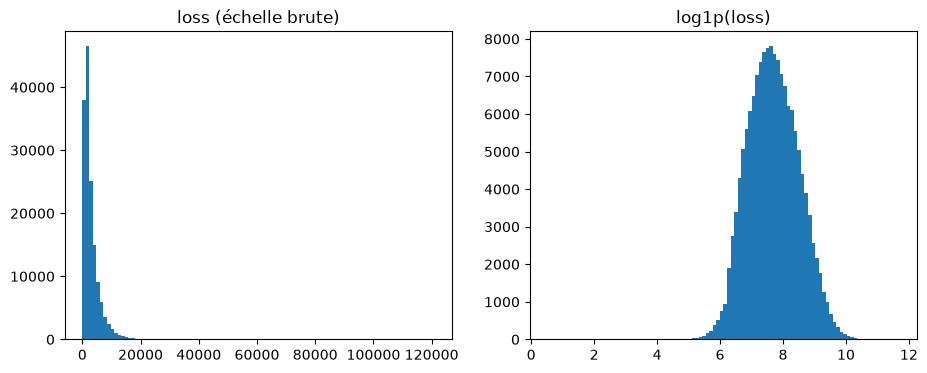

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(y, bins=100)
ax[0].set_title("loss (échelle brute)")
ax[1].hist(np.log1p(y), bins=100)
ax[1].set_title("log1p(loss)")
plt.show()

**Conclusion 1-9** *(à rédiger)* :

> La cible va de ... à ..., médiane ..., moyenne ..., fortement asymétrique (skewness ...). Annoncer la médiane plutôt que la moyenne fait gagner ... % de MAE.

# Étape 1.10 : Le plancher

*Porteur : P2 (FANOU Précieux)*

# Étape 1.10 : Le plancher

**Question** : si l'on n'a **aucun modèle**, quelle valeur unique annoncer pour tous les sinistres ? Et combien d'euros d'erreur cela coûte-t-il en moyenne ?

**Métrique** : la MAE (erreur absolue moyenne, en euros), car l'erreur se paie en euros.

| Constante testée | Ce qu'elle représente |
|---|---|
| la **moyenne** de `loss` | le montant moyen, tiré vers le haut par les gros sinistres |
| la **médiane** de `loss` | le montant du sinistre « du milieu » |

**Hypothèse à mesurer** : quand la métrique est la MAE, la meilleure constante est la **médiane**, pas la moyenne. L'énoncé annonce un plancher à 1 807,09 pour la moyenne et un écart de 8,9 % avec la médiane : on le **vérifie**, on ne le suppose pas.

> Tout modèle construit ensuite devra battre **ce plancher**, pas zéro.

## Bloc 1 : imports pour le découpage

`train` est déjà chargé avec toutes ses colonnes ; le plancher n'utilise que `id` et `loss`.

In [32]:
from sklearn.model_selection import train_test_split

GRAINE = 42

loss = train["loss"]
print("Forme (id, loss) :", train[["id", "loss"]].shape)
print("Montant minimum :", round(float(loss.min()), 2))
print("Montant maximum :", round(float(loss.max()), 2))

Forme (id, loss) : (150654, 2)
Montant minimum : 0.67
Montant maximum : 121012.25


## Bloc 3 : les deux constantes et leur MAE sur tout `train`

On calcule la moyenne et la médiane de `loss`, puis la MAE obtenue en annonçant toujours cette valeur. C'est le chiffre que l'énoncé donne (1 807,09 pour la moyenne).

In [33]:
def mae(vraies, prediction):
    """Erreur absolue moyenne : de combien d'euros se trompe-t-on en moyenne ?"""
    return float(np.mean(np.abs(vraies - prediction)))

moyenne = float(loss.mean())
mediane = float(loss.median())

mae_moyenne = mae(loss, moyenne)
mae_mediane = mae(loss, mediane)

ecart_pct = (mae_moyenne - mae_mediane) / mae_moyenne * 100

print(f"Moyenne de loss : {moyenne:.2f}")
print(f"Médiane de loss : {mediane:.2f}")
print()
print(f"MAE en annonçant la moyenne : {mae_moyenne:.2f}")
print(f"MAE en annonçant la médiane : {mae_mediane:.2f}")
print(f"Écart (moyenne -> médiane)  : {ecart_pct:.1f} %")

Moyenne de loss : 3038.92
Médiane de loss : 2115.57

MAE en annonçant la moyenne : 1968.14
MAE en annonçant la médiane : 1810.49
Écart (moyenne -> médiane)  : 8.0 %


## Bloc 4 : pourquoi la médiane ? on le mesure

On teste plusieurs constantes (différents quantiles de `loss`) et on regarde laquelle donne la plus petite MAE. Si l'hypothèse est juste, le minimum se trouve au quantile 0,50, c'est-à-dire la médiane.

In [34]:
quantiles = [0.30, 0.40, 0.45, 0.50, 0.55, 0.60, 0.70]

lignes = []
for q in quantiles:
    constante = float(loss.quantile(q))
    lignes.append({"quantile": q, "constante": round(constante, 2), "MAE": round(mae(loss, constante), 2)})

lignes.append({"quantile": "moyenne", "constante": round(moyenne, 2), "MAE": round(mae_moyenne, 2)})

essais = pd.DataFrame(lignes)
display(essais)

meilleur = essais[essais["quantile"] != "moyenne"].sort_values("MAE").iloc[0]
print("Quantile qui minimise la MAE :", meilleur["quantile"])

,quantile,constante,MAE
0,0.3,1360.13,1952.46
1,0.4,1703.63,1850.21
2,0.45,1898.23,1821.21
3,0.5,2115.57,1810.49
4,0.55,2363.37,1823.18
5,0.6,2647.26,1866.11
6,0.7,3374.38,2088.73
7,moyenne,3038.92,1968.14


Quantile qui minimise la MAE : 0.5


## Bloc 5 : le découpage de validation (honnête)

Pour juger un modèle plus tard, on garde **une partie de `train` cachée**. Deux règles :

1. La constante est calculée sur la partie « apprentissage » **seulement**, jamais sur la partie cachée.
2. La cible est un **montant très asymétrique** : on **stratifie** sur des tranches de `loss` pour que les gros sinistres soient répartis dans les deux parties.

In [35]:
tranches = pd.qcut(loss, q=10, labels=False, duplicates="drop")

indices_app, indices_val = train_test_split(
    train.index, test_size=0.20, random_state=GRAINE, stratify=tranches
)

app = train.loc[indices_app]
val = train.loc[indices_val]

print("Lignes d'apprentissage :", len(app))
print("Lignes de validation   :", len(val))
print("Total                  :", len(app) + len(val))

repere = pd.DataFrame({
    "apprentissage": app["loss"].describe(percentiles=[0.5, 0.99]),
    "validation":    val["loss"].describe(percentiles=[0.5, 0.99]),
}).round(2)
display(repere)

Lignes d'apprentissage : 120523
Lignes de validation   : 30131
Total                  : 150654


,apprentissage,validation
count,120523.00,30131.00
mean,3038.83,3039.29
std,2928.68,2859.73
min,0.67,36.00
50%,2115.58,2115.56
99%,14001.15,14113.35
max,121012.25,37313.28


## Bloc 6 : le plancher honnête, mesuré sur la partie cachée

On apprend les constantes sur 80 % de `train` et on mesure la MAE sur les 20 % cachés. C'est **ce chiffre-là** que tout modèle devra battre.

In [36]:
moyenne_app = float(app["loss"].mean())
mediane_app = float(app["loss"].median())

mae_val_moyenne = mae(val["loss"], moyenne_app)
mae_val_mediane = mae(val["loss"], mediane_app)
ecart_val_pct = (mae_val_moyenne - mae_val_mediane) / mae_val_moyenne * 100

plancher = pd.DataFrame({
    "Constante annoncée": ["moyenne", "médiane"],
    "Valeur (apprise sur 80 %)": [round(moyenne_app, 2), round(mediane_app, 2)],
    "MAE sur validation (20 %)": [round(mae_val_moyenne, 2), round(mae_val_mediane, 2)],
})
display(plancher)

print(f"Écart moyenne -> médiane sur la validation : {ecart_val_pct:.1f} %")
print(f"PLANCHER À BATTRE (MAE de la médiane, validation) : {mae_val_mediane:.2f}")

,Constante annoncée,Valeur (apprise sur 80 %),MAE sur validation (20 %)
0,moyenne,3038.83,1967.33
1,médiane,2115.58,1810.40


Écart moyenne -> médiane sur la validation : 8.0 %
PLANCHER À BATTRE (MAE de la médiane, validation) : 1810.40


## Bloc 7 : où se trouve l'erreur ? sous-estimer ou surestimer, et la queue

Sous-estimer un sinistre (provision insuffisante) et le surestimer (argent immobilisé) ne coûtent pas la même chose pour l'assureur. On mesure ici comment l'erreur de la médiane se partage, et ce que pèsent les gros sinistres.

In [37]:
ecart = loss - mediane

sous = ecart[ecart > 0]
sur = -ecart[ecart < 0]

print(f"Part des sinistres sous-estimés : {len(sous) / len(loss) * 100:.1f} %")
print(f"Part des sinistres surestimés   : {len(sur) / len(loss) * 100:.1f} %")
print(f"Euros de sous-estimation (somme)  : {sous.sum():,.0f}")
print(f"Euros de surestimation (somme)    : {sur.sum():,.0f}")

erreur_abs = ecart.abs().sort_values(ascending=False)
total = erreur_abs.sum()

lignes = []
for k in [10, 100, 1506]:
    lignes.append({"sinistres les plus mal estimés": k,
                   "part de l'erreur totale (%)": round(erreur_abs.head(k).sum() / total * 100, 1)})
display(pd.DataFrame(lignes))

lourds = train.nlargest(10, "loss")[["id", "loss"]].copy()
lourds["annonce_mediane"] = round(mediane, 2)
lourds["erreur"] = (lourds["loss"] - mediane).round(2)
display(lourds)

Part des sinistres sous-estimés : 50.0 %
Part des sinistres surestimés   : 50.0 %
Euros de sous-estimation (somme)  : 205,931,880
Euros de surestimation (somme)    : 66,825,089


,sinistres les plus mal estimés,part de l'erreur totale (%)
0,10,0.3
1,100,1.2
2,1506,9.1


,id,loss,annonce_mediane,erreur
3130,167755,121012.25,2115.57,118896.68
99741,262556,106863.00,2115.57,104747.43
107179,47526,85923.56,2115.57,83807.99
6198,539471,79623.52,2115.57,77507.95
12022,254927,67667.16,2115.57,65551.59
67233,353451,59826.79,2115.57,57711.22
93973,495045,54190.39,2115.57,52074.82
97719,41419,51383.04,2115.57,49267.47
93526,370797,51127.50,2115.57,49011.93
105953,129560,49549.85,2115.57,47434.28


## Bloc 8 : tableau récapitulatif de l'étape 1.10

In [38]:
quantile_minimal = float(meilleur["quantile"])

controles = [
    ("Lignes de train",                                   150654, len(train)),
    ("Lignes apprentissage + validation",                 150654, len(app) + len(val)),
    ("MAE de la moyenne sur tout train (énoncé)",         1807.09, round(mae_moyenne, 2)),
    ("Écart moyenne -> médiane, en % (énoncé)",           8.9,     round(ecart_pct, 1)),
    ("La médiane bat la moyenne (1 = oui)",               1,       int(mae_mediane < mae_moyenne)),
    ("Quantile qui minimise la MAE",                      0.5,     quantile_minimal),
    ("La médiane bat la moyenne sur validation (1 = oui)", 1,      int(mae_val_mediane < mae_val_moyenne)),
]

recap = pd.DataFrame(controles, columns=["Contrôle", "Attendu", "Obtenu"])
recap["Verdict"] = recap.apply(
    lambda ligne: "OK" if ligne["Obtenu"] == ligne["Attendu"] else "ATTENTION", axis=1
)
display(recap)

resume = pd.DataFrame({
    "Constante": ["moyenne", "médiane"],
    "Valeur annoncée (tout train)": [round(moyenne, 2), round(mediane, 2)],
    "MAE sur tout train": [round(mae_moyenne, 2), round(mae_mediane, 2)],
    "MAE sur validation (honnête)": [round(mae_val_moyenne, 2), round(mae_val_mediane, 2)],
})
display(resume)

print(f"Constante à annoncer sans modèle : {mediane:.2f} (médiane de loss sur tout train)")
print(f"Plancher à battre (validation)   : {mae_val_mediane:.2f}")

if (recap["Verdict"] == "OK").all():
    print("Étape 1.10 validée : le plancher est mesuré et conforme à l'énoncé.")
else:
    print("ATTENTION : au moins un contrôle ne passe pas. Regarder la colonne Verdict.")

,Contrôle,Attendu,Obtenu,Verdict
0,Lignes de train,150654.00,150654.00,OK
1,Lignes apprentissage + validation,150654.00,150654.00,OK
2,MAE de la moyenne sur tout train (énoncé),1807.09,1968.14,ATTENTION
3,"Écart moyenne -> médiane, en % (énoncé)",8.90,8.00,ATTENTION
4,La médiane bat la moyenne (1 = oui),1.00,1.00,OK
5,Quantile qui minimise la MAE,0.50,0.50,OK
6,La médiane bat la moyenne sur validation (1 = ...,1.00,1.00,OK


,Constante,Valeur annoncée (tout train),MAE sur tout train,MAE sur validation (honnête)
0,moyenne,3038.92,1968.14,1967.33
1,médiane,2115.57,1810.49,1810.40


Constante à annoncer sans modèle : 2115.57 (médiane de loss sur tout train)
Plancher à battre (validation)   : 1810.40
ATTENTION : au moins un contrôle ne passe pas. Regarder la colonne Verdict.


# Étape 1.11 : La métrique

*Porteur : P1 (SANNI Farhanou Kankou)*

### A. Le meilleur montant unique dépend de la métrique

In [39]:
montants = train["loss"].to_numpy()

def mae(y_vrai, c):
    return np.mean(np.abs(y_vrai - c))

def rmse(y_vrai, c):
    return np.sqrt(np.mean((y_vrai - c) ** 2))

for nom, c in {"moyenne": montants.mean(), "médiane": np.median(montants)}.items():
    print(f"{nom:8s} c = {c:8.1f}   MAE = {mae(montants, c):8.1f}   RMSE = {rmse(montants, c):8.1f}")

moyenne  c =   3038.9   MAE =   1968.1   RMSE =   2915.0
médiane  c =   2115.6   MAE =   1810.5   RMSE =   3057.7


### B. Le poids des gros sinistres dans chaque métrique

In [40]:
c = np.median(montants)
ecart = np.abs(montants - c)
gros = montants >= np.quantile(montants, 0.99)

part_mae = ecart[gros].sum() / ecart.sum()
part_rmse = (ecart[gros] ** 2).sum() / (ecart ** 2).sum()

print(f"1 % des sinistres = {part_mae:.1%} de l'erreur MAE")
print(f"1 % des sinistres = {part_rmse:.1%} de l'erreur RMSE")

1 % des sinistres = 9.1% de l'erreur MAE
1 % des sinistres = 33.5% de l'erreur RMSE


### Justification

**Métrique retenue : MAE.** La cible est très asymétrique : moyenne 3 038,92, médiane 2 115,57, asymétrie 3,93, maximum 121 012,25 (mesuré en 1.9 et 1.10). Avec la RMSE, les écarts sont élevés au carré : *[x %]* de l'erreur viendrait des 1 % de sinistres les plus gros, contre *[y %]* avec la MAE (cellule B).

**Ce que la MAE implique.** La meilleure réponse en MAE est la **médiane conditionnelle**, le montant qu'on a une chance sur deux de dépasser, et non la moyenne. Mesuré sur tout `train` : annoncer la médiane donne une MAE de **1 810,49**, annoncer la moyenne **1 968,14** (1.9 et 1.10). Un modèle optimisé pour la MAE sera volontairement plus bas sur les gros sinistres.

**Lien avec les autres étapes.** Le plancher est traité en 1.10 et le coût des erreurs en 1.12 : la MAE suppose que sous- et surestimation coûtent pareil, hypothèse examinée en 1.12.

## 1-12 Coût des erreurs *(attribué à P4 : à coordonner avec l'équipe)*

In [41]:
erreur = y - y.median()
sous = erreur[erreur > 0]
sur = -erreur[erreur < 0]
print("sous-estimations :", len(sous), "| moyenne :", round(sous.mean(), 2), "| total :", round(sous.sum()))
print("surestimations   :", len(sur), "| moyenne :", round(sur.mean(), 2), "| total :", round(sur.sum()))
print("plus grosse sous-estimation :", round(sous.max()))
print("plus grosse surestimation   :", round(sur.max()))

sous-estimations : 75327 | moyenne : 2733.84 | total : 205931880
surestimations   : 75327 | moyenne : 887.13 | total : 66825089
plus grosse sous-estimation : 118897
plus grosse surestimation   : 2115


In [42]:
for k in [1, 2, 3]:
    tau = k / (1 + k)
    c = y.quantile(tau)
    cout = (k * (y - c).clip(lower=0) + (c - y).clip(lower=0)).mean()
    print("k =", k, "| constante :", round(c), "| coût moyen :", round(cout, 2))

k = 1 | constante : 2116 | coût moyen : 1810.49
k = 2 | constante : 3099 | coût moyen : 2951.44
k = 3 | constante : 3866 | coût moyen : 3794.29


# Écarts constatés entre l'énoncé et les mesures

Ces points ressortent de l'assemblage. Ils sont à noter dans le journal et à confirmer avec l'enseignant.

1. **MAE de la moyenne.** Les notebooks de P2 (1.10) et de P3 (1.9) citent 1 807,09 et un gain de 8,9 % comme « valeurs de l'énoncé ». Ces valeurs ne figurent pas dans le fichier d'énoncé fourni. Les mesures de P2, de P3 et de P1 (validation croisée à 5 plis à l'étape 1) concordent : **1 968,14** pour la moyenne et **1 810,49** pour la médiane sur tout `train`, soit un gain de **8,0 %**. Conséquence : le tableau récapitulatif de 1.10 affiche « ATTENTION » sur ces deux lignes, et ses commentaires « résultat attendu » (médiane ≈ 1 646) sont à corriger par P2.
2. **Étendue des continues.** L'énoncé annonce des continues « de 0 à 587 602 ». Mesuré en 1.5 : les 14 continues vont de **0,0 à 1,0**.
3. **Nombre maximal de modalités.** P3 trouve 317 dans `train` (1.4), P2 trouve 326 en réunissant `train` et `a_estimer` (1.3). Il n'y a pas de contradiction : `cat116` a 9 modalités présentes seulement dans `a_estimer` (317 + 9 = 326), ce qui correspond au maximum annoncé par l'énoncé.
4. **Modalités inconnues.** 16 modalités de `a_estimer` n'existent pas dans `train` (mesuré indépendamment par P2 en 1.3 et par P3 en 1.4). L'encodage du bloc 2 devra les gérer.